# 4 — Validate Baseline Model

## Objective
Evaluate the trained RGB-feature logistic-regression baseline on the dataset's existing **validation** images. Inspect both quantitative performance and individual examples of classification errors.

## Inputs
- `../data/raw/valid/`: validation images.
- `../data/raw/valid/_annotations.coco.json`: COCO-style image records and defect annotations used to derive PASS/FAIL reference labels.
- `../models/baseline_logistic_regression.joblib`: the trained classifier from Notebook 04.

## Workflow
1. Read the validation annotations and assign `FAIL` when an image has an annotation; otherwise assign `PASS`.
2. Extract the same six RGB features used for model training.
3. Load the saved model and predict validation labels.
4. Examine accuracy, per-class precision/recall/F1, and the confusion matrix.
5. Review false-PASS predictions and visually inspect images labelled PASS.

## Outputs
Displayed labels, predictions, performance metrics, a confusion matrix, and image grids.

**Interpretation caution:** The annotation-based labelling rule is an assumption: an unannotated image is treated as PASS. Inspect questionable cases before drawing conclusions about model performance. No new random split is performed in this notebook.

### Running this review copy

Use the original project `notebooks` folder as the kernel working directory; this copy is stored in its `for review` subfolder. The existing `../data` and `../models` paths depend on that working directory. Run the workflow in order in a fresh kernel. Stored outputs are retained from the source notebook and were not regenerated during this readability review.

### Verify environment and import packages
Confirm the active Python interpreter and load imaging, plotting, and evaluation libraries.

In [1]:
# Display the interpreter used by this notebook for environment troubleshooting.
import sys
print(sys.executable)

c:\Users\bengr\OneDrive - Monash University\Desktop\Uni\3001 Numerical Methods and Machine Learning\Pork Rasher Inspection\notebooks\.venv\Scripts\python.exe


In [2]:
# Load image-processing, table, plotting, annotation, and evaluation packages.
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

### Locate and read validation annotations
Point to the validation folder already supplied with the dataset; no new split is made.

In [3]:
# Reference the pre-existing validation folder and its COCO annotation file.

PROJECT_ROOT = Path("..")

VALID_IMAGE_DIR = PROJECT_ROOT / "data" / "raw" / "valid"
VALID_ANNOTATIONS = VALID_IMAGE_DIR / "_annotations.coco.json"

In [4]:
# Parse image metadata and defect annotations from the COCO JSON file.
with open(VALID_ANNOTATIONS, "r") as f:
    coco_data = json.load(f)

### Construct ground-truth validation labels
Find annotated images and apply the existing annotation-present → FAIL rule.

In [5]:
# Build a set of image IDs with at least one defect annotation.
# Set membership avoids scanning every annotation for each image.

annotated_image_ids = {
    annotation["image_id"]
    for annotation in coco_data["annotations"]
}

In [6]:
# Derive a single PASS/FAIL label for each validation image.
# This assumes unannotated images represent acceptable packages.
validation_labels = []

for image in coco_data["images"]:

    image_id = image["id"]
    filename = image["file_name"]

    if image_id in annotated_image_ids:
        label = "FAIL"
    else:
        label = "PASS"

    validation_labels.append({
        "filename": filename,
        "label": label
    })

valid_labels_df = pd.DataFrame(validation_labels)

In [7]:
# Check class counts to understand validation-set imbalance.
print(valid_labels_df["label"].value_counts())
print("\nTotal validation images:", len(valid_labels_df))

label
FAIL    106
PASS     14
Name: count, dtype: int64

Total validation images: 120


### Extract consistent RGB features
Use the same feature definitions as Notebook 04 for every validation image.

In [8]:
def extract_rgb_features(image_path):
    """Calculate six image-level RGB statistics for a validation image.

    Parameters
    ----------
    image_path : str or pathlib.Path
        Location of the image to analyse.

    Returns
    -------
    dict
        Mean and standard deviation for each RGB colour channel.

    Raises
    ------
    ValueError
        If OpenCV cannot load the requested image.

    Notes
    -----
    OpenCV reads images in BGR order, so the loaded pixels are converted
    to RGB before calculating features to match the training feature set.
    """

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not load image: {image_path}")

    # OpenCV loads images as BGR
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    red = image_rgb[:, :, 0]
    green = image_rgb[:, :, 1]
    blue = image_rgb[:, :, 2]

    return {
        "mean_red": np.mean(red),
        "mean_green": np.mean(green),
        "mean_blue": np.mean(blue),
        "std_red": np.std(red),
        "std_green": np.std(green),
        "std_blue": np.std(blue)
    }

In [9]:
# Compute RGB features for every labelled validation image.
# The image-level feature definitions must match the training notebook.
validation_rows = []

for _, row in valid_labels_df.iterrows():

    image_path = VALID_IMAGE_DIR / row["filename"]

    features = extract_rgb_features(image_path)

    features["filename"] = row["filename"]
    features["label"] = row["label"]

    validation_rows.append(features)

valid_features_df = pd.DataFrame(validation_rows)

valid_features_df.head()

,mean_red,mean_green,mean_blue,std_red,std_green,std_blue,filename,label
0,49.399792,47.326512,48.664519,42.643538,34.142742,35.183197,frame_with_red_8649_jpg.rf.a4d923187143603a280...,FAIL
1,45.959835,43.577181,44.300898,37.444479,28.650479,29.526516,frame_with_red_2115_jpg.rf.2eb3c4cff72bd0c8282...,PASS
2,50.669578,47.752994,49.097765,42.503044,32.754078,33.678070,frame_with_red_8627_jpg.rf.e0f16b203d1ac259b6c...,FAIL
3,56.327726,52.025087,53.961443,48.824981,36.230730,37.636808,frame_with_red_2289_jpg.rf.e4cabf0fac8d843cef9...,FAIL
4,58.202109,53.662752,54.142541,55.981233,43.544077,43.061124,frame_with_red_8526_jpg.rf.8a95c208e25b872ba67...,FAIL


### Assemble model inputs and load the baseline
Predictors must have the same names and ordering as during training.

In [10]:
# Use the exact same six predictor columns and their training-time order.
#Seperate Features from correct answers
feature_columns = [
    "mean_red",
    "mean_green",
    "mean_blue",
    "std_red",
    "std_green",
    "std_blue"
]

X_valid = valid_features_df[feature_columns]
y_valid = valid_features_df["label"]

In [11]:
# Import the joblib library for saving and loading trained models.
import joblib

In [12]:
# Reload the fitted baseline saved by Notebook 04.

MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "baseline_logistic_regression.joblib"
)

model = joblib.load(MODEL_PATH)


### Predict and inspect individual classifications
Compare each prediction with the annotation-derived label.

In [13]:
# Generate predictions from the fixed validation-image features.
y_pred = model.predict(X_valid)

In [14]:
# Compare predictions to reference labels for per-image error analysis.
results_df = valid_features_df[
    ["filename", "label"]
].copy()

results_df["prediction"] = y_pred

results_df["correct"] = (
    results_df["label"] == results_df["prediction"]
)
#Printing short results table
results_df.head(20)

,filename,label,prediction,correct
0,frame_with_red_8649_jpg.rf.a4d923187143603a280...,FAIL,FAIL,True
1,frame_with_red_2115_jpg.rf.2eb3c4cff72bd0c8282...,PASS,FAIL,False
2,frame_with_red_8627_jpg.rf.e0f16b203d1ac259b6c...,FAIL,FAIL,True
3,frame_with_red_2289_jpg.rf.e4cabf0fac8d843cef9...,FAIL,FAIL,True
4,frame_with_red_8526_jpg.rf.8a95c208e25b872ba67...,FAIL,FAIL,True
5,frame_with_red_531_jpg.rf.d1bf4eab747883d5e9fa...,FAIL,FAIL,True
6,frame_with_red_1308_jpg.rf.4fe453ba69054077d74...,PASS,FAIL,False
7,frame_with_red_6194_jpg.rf.6c5b8fe814fbf13689b...,FAIL,FAIL,True
8,frame_with_red_9311_jpg.rf.42e8694a15dd5e3b34e...,FAIL,FAIL,True
9,frame_with_red_2617_jpg.rf.a1009fb1133a89370a9...,FAIL,FAIL,True


### Evaluate classification performance
Review overall accuracy and class-level metrics; class imbalance makes accuracy alone insufficient.

In [15]:
# Measure the proportion of correctly classified validation images.

accuracy = accuracy_score(y_valid, y_pred)

print(f"Validation accuracy: {accuracy:.2%}")

Validation accuracy: 80.83%


In [16]:
# Report precision, recall, F1, and support for each class.

print(
    classification_report(
        y_valid,
        y_pred,
        digits=3
    )
)

              precision    recall  f1-score   support

        FAIL      0.888     0.896     0.892       106
        PASS      0.154     0.143     0.148        14

    accuracy                          0.808       120
   macro avg      0.521     0.520     0.520       120
weighted avg      0.802     0.808     0.805       120



### Confusion matrix
Display how actual FAIL and PASS images are classified by the model.

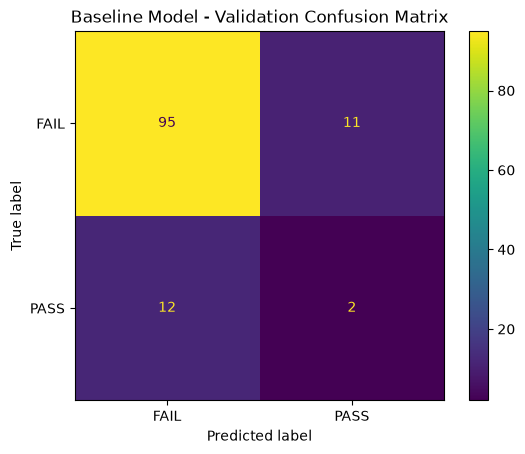

In [17]:
# Organise prediction outcomes by actual and predicted class.
#Generate confusion matrix

cm = confusion_matrix(
    y_valid,
    y_pred,
    labels=["FAIL", "PASS"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["FAIL", "PASS"]
)

display.plot()
plt.title("Baseline Model - Validation Confusion Matrix")
plt.show()

### Review errors and potentially mislabeled images
Inspect cases where defects were predicted as PASS, then view the dataset’s PASS-labelled images.

In [18]:
# Identify actual FAIL images misclassified as PASS (missed defects).
#Looking at fail images incorrectly predicted as PASS
false_passes = results_df[
    (results_df["label"] == "FAIL") &
    (results_df["prediction"] == "PASS")
]

print("FAIL images incorrectly predicted as PASS:")
print(len(false_passes))

false_passes

FAIL images incorrectly predicted as PASS:
11


,filename,label,prediction,correct
20,frame_with_red_1393_jpg.rf.df87c31d694443cac64...,FAIL,PASS,False
23,frame_with_red_6690_jpg.rf.c68f24776923469b0ff...,FAIL,PASS,False
40,frame_with_red_1177_jpg.rf.fbd066a9a1201014b56...,FAIL,PASS,False
58,frame_with_red_7267_jpg.rf.1c3350f5e48c69a6295...,FAIL,PASS,False
68,frame_with_red_1226_jpg.rf.02bacabc1b116d61d0e...,FAIL,PASS,False
80,frame_with_red_1232_jpg.rf.d9057a111fd0cccdc34...,FAIL,PASS,False
81,frame_with_red_5859_jpg.rf.86dc5555f35b4b32639...,FAIL,PASS,False
98,frame_with_red_7030_jpg.rf.25ac5ef78763f4b7def...,FAIL,PASS,False
102,frame_with_red_215_jpg.rf.9c65a2aa269df55e39dd...,FAIL,PASS,False
105,frame_with_red_1572_jpg.rf.b3d4df3f1c03a90a627...,FAIL,PASS,False


In [19]:
# Select images labelled PASS for additional visual quality checks.
pass_images = valid_features_df[
    valid_features_df["label"] == "PASS"
]

print("Number of PASS images:", len(pass_images))

pass_images[["filename", "label"]]

Number of PASS images: 14


,filename,label
1,frame_with_red_2115_jpg.rf.2eb3c4cff72bd0c8282...,PASS
6,frame_with_red_1308_jpg.rf.4fe453ba69054077d74...,PASS
26,frame_with_red_1892_jpg.rf.ff8ef2be9ae1cf6ba3e...,PASS
42,frame_with_red_1948_jpg.rf.b6a1ea751c46433d7ee...,PASS
44,frame_with_red_4925_jpg.rf.2224f997f85781bb8b4...,PASS
50,frame_with_red_1688_jpg.rf.7a009dfca1f2ca00c87...,PASS
51,frame_with_red_8049_jpg.rf.9c9541adc7706542de7...,PASS
55,frame_with_red_1195_jpg.rf.5edff0d6dd0ba49c346...,PASS
59,frame_with_red_1456_jpg.rf.2496f64ab3142e836dd...,PASS
60,frame_with_red_132_jpg.rf.24dd72084f9af6260fd9...,PASS


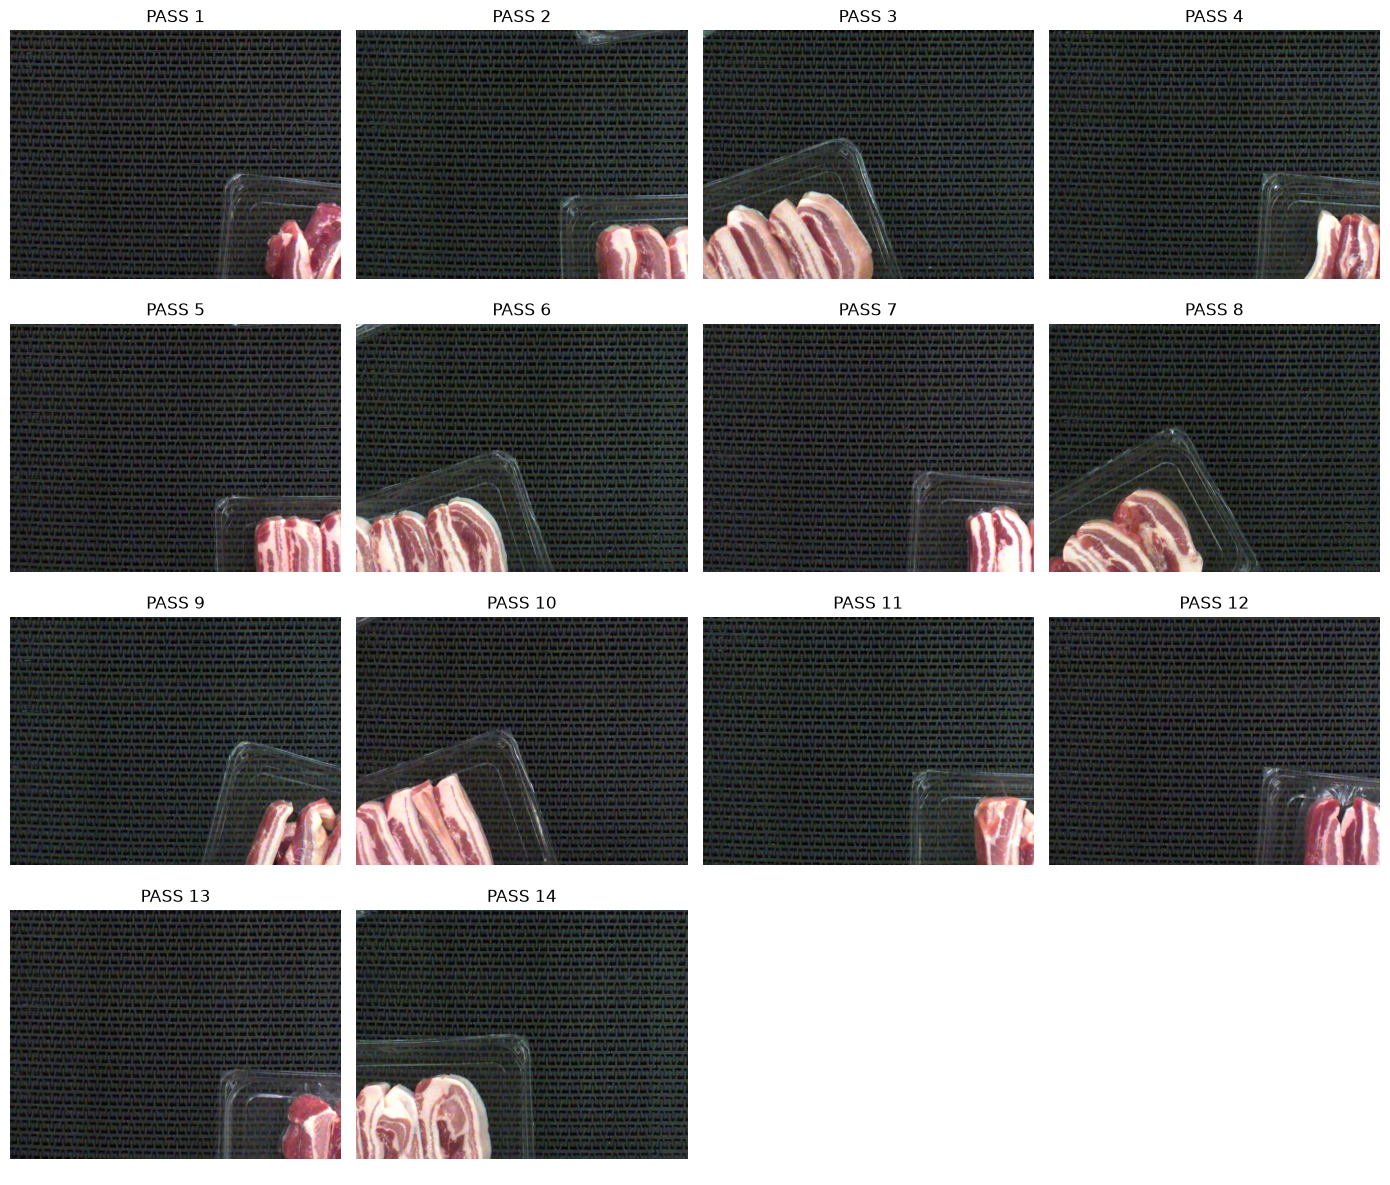

In [20]:
# Display a grid of PASS-labelled images to inspect the labelling assumption.
fig, axes = plt.subplots(4, 4, figsize=(14, 12))
axes = axes.flatten()

for i, (_, row) in enumerate(pass_images.iterrows()):
    
    image_path = VALID_IMAGE_DIR / row["filename"]
    
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    axes[i].imshow(image)
    axes[i].set_title(f"PASS {i + 1}")
    axes[i].axis("off")

# Hide unused panels
for j in range(len(pass_images), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

Reviewing all validation pass images, it appears they do not have obvious defects, and thus the original assumption is sustained